# Burning Calendar & Historical Analog: Tìm Năm Tương Đồng Nhất & Dự Phóng FRP

Notebook này thực hiện pipeline so sánh mùa cháy rừng năm hiện tại (`2025`) với dữ liệu lịch sử đã chuẩn hóa (`2000–2024`) trong thư mục **`harmonize_final`** (`{year}.parquet`, 25 cột).

### Tóm tắt phương pháp
1. **Khử trùng lặp theo ngày & ô lưới H3**: Gom dữ liệu về từng cặp `(h3_res7, acq_date)` (`MAX(frp)`), loại bỏ sai lệch do nhiều vệ tinh cùng bay qua một đám cháy trong ngày.
2. **Tạo vector tuần tận dụng 3 tín hiệu vật lý (không dùng hằng số tự đặt, cắt đúng tới ngày cháy đang xét `cutoff_doy`)**:
   - **Công suất bức xạ cháy (`FRP`)**
   - **Tỷ lệ chênh nhiệt tự nhiên**: `(bright_mir - bright_tir) / bright_tir`
   - **Trọng số độ tin cậy (`conf`)**: `(1.0 * conf_h + 0.6 * conf_n + 0.2 * conf_l) / point_count`
3. **Chấm điểm tương đồng (`Cosine Similarity + DTW`)**:
   - `final_score_pct = 0.5 * Cosine + 0.5 * DTW` (thang `0–100%`)
   - Khoảng tin cậy quanh đường năm tương đồng: **`± n%` với `n = 100 - final_score_pct`** (điểm tương đồng càng cao thì biên sai số càng hẹp).
4. **Chạy giả lập 3 mốc thời gian**: **Tháng 6 (`2025-06-30`)**, **Tháng 7 (`2025-07-31`)**, **Tháng 8 (`2025-08-31`)** và vẽ biểu đồ FRP theo tuần.

---

### Hướng dẫn kết nối thư mục `Được chia sẻ với tôi / harmonize_final` trên Google Colab
Vì `/content/drive` trên Google Colab chỉ truy cập được các thư mục nằm trong **`MyDrive`**, **`Shareddrives`** hoặc lối tắt **`.shortcut-targets-by-id`**, nếu thư mục `harmonize_final` đang nằm trong mục **"Được chia sẻ với tôi" (Shared with me)** trên Google Drive của bạn:
1. Mở Google Drive trên trình duyệt $\rightarrow$ vào mục **Được chia sẻ với tôi**.
2. Nhấp chuột phải vào thư mục **`harmonize_final`** $\rightarrow$ chọn **Sắp xếp (Organize)** $\rightarrow$ **Thêm lối tắt (Add shortcut)**.
3. Chọn **Drive của tôi (My Drive)** (đặt ở ngoài cùng hoặc trong `MyDrive/NasaHackathonData`).

Ô code bên dưới sẽ tự động quét cả `MyDrive`, `.shortcut-targets-by-id`, `Shareddrives` và fallback sang đường dẫn local `C:\Uni\261\Space Apps Challenge\harmonize_data` nếu chạy trên máy tính cá nhân.

In [1]:
# ==============================================================================
# Ô 2: CÀI ĐẶT THƯ VIỆN, MOUNT GOOGLE DRIVE & TỰ ĐỘNG TÌM `harmonize_final`
# ==============================================================================
import importlib.util
import os
import re
import subprocess
import sys
from collections import deque

for mod_name, pip_name in [
    ("duckdb", "duckdb"),
    ("pandas", "pandas"),
    ("numpy", "numpy"),
    ("matplotlib", "matplotlib"),
]:
    if importlib.util.find_spec(mod_name) is None:
        print(f"Đang cài đặt {pip_name}...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name])

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Nếu muốn chỉ định thủ công đường dẫn thư mục chứa *.parquet, điền vào biến dưới đây:
MANUAL_DATA_DIR = None

IS_COLAB = bool(
    os.environ.get("COLAB_RELEASE_TAG")
    or os.environ.get("COLAB_GPU") is not None
    or os.path.isdir("/content")
)

if IS_COLAB:
    from google.colab import drive
    if not os.path.isdir("/content/drive/MyDrive"):
        drive.mount("/content/drive")


def _list_year_parquets(dir_path: str) -> list[str]:
    try:
        if not os.path.isdir(dir_path):
            return []
        files = []
        with os.scandir(dir_path) as it:
            for entry in it:
                if entry.name.endswith(".parquet") and entry.is_file(follow_symlinks=True):
                    files.append(entry.name)
        return sorted(files)
    except OSError:
        return []


def _has_year_parquets(dir_path: str) -> bool:
    files = _list_year_parquets(dir_path)
    year_files = [f for f in files if re.match(r"^(19|20)\d{2}\.parquet$", f)]
    return len(year_files) >= 2 or ("2024.parquet" in files and "2025.parquet" in files)


def find_harmonize_final_dir(max_depth: int = 4) -> str:
    if MANUAL_DATA_DIR and _list_year_parquets(MANUAL_DATA_DIR):
        return MANUAL_DATA_DIR

    quick_candidates = [
        "/content/drive/MyDrive/harmonize_final",
        "/content/drive/MyDrive/NasaHackathonData/harmonize_final",
        "/content/drive/MyDrive/harmonize_data",
        "/content/drive/MyDrive/NasaHackathonData/harmonize_data",
        r"C:\Uni\261\Space Apps Challenge\harmonize_data",
        os.path.abspath(os.path.join(os.getcwd(), "..", "harmonize_data")),
        os.path.abspath(os.path.join(os.getcwd(), "harmonize_data")),
    ]
    for cand in quick_candidates:
        if _has_year_parquets(cand):
            return cand

    search_roots = [
        "/content/drive/.shortcut-targets-by-id",
        "/content/drive/MyDrive",
        "/content/drive/Shareddrives",
    ]
    visited_real = set()
    queue = deque()
    for root in search_roots:
        if os.path.isdir(root):
            real = os.path.realpath(root)
            if real not in visited_real:
                visited_real.add(real)
                queue.append((root, 0))

    fallback_match = None
    priority_names = ("harmonize_final", "harmonize", "nasahackathondata", "nasa", "fire")
    while queue:
        cur_dir, depth = queue.popleft()
        base_lower = os.path.basename(cur_dir).lower()
        if depth > 0 and _has_year_parquets(cur_dir):
            if base_lower == "harmonize_final":
                return cur_dir
            if fallback_match is None:
                fallback_match = cur_dir
        if depth >= max_depth:
            continue
        try:
            with os.scandir(cur_dir) as it:
                entries = [
                    e for e in it
                    if not e.name.startswith(".") and e.is_dir(follow_symlinks=True)
                ]
        except OSError:
            continue
        entries.sort(key=lambda e: (0 if any(p in e.name.lower() for p in priority_names) else 1, e.name.lower()))
        for entry in entries:
            try:
                real = os.path.realpath(entry.path)
            except OSError:
                continue
            if real not in visited_real:
                visited_real.add(real)
                queue.append((entry.path, depth + 1))

    if fallback_match is not None:
        return fallback_match

    raise FileNotFoundError(
        "Không tìm thấy thư mục `harmonize_final` chứa các file `{year}.parquet`! "
        "Nếu thư mục đang ở 'Được chia sẻ với tôi', hãy nhấp chuột phải -> Sắp xếp -> Thêm lối tắt vào 'Drive của tôi' rồi chạy lại ô này."
    )


DATA_DIR = find_harmonize_final_dir()
PARQUET_FILES = _list_year_parquets(DATA_DIR)
YEARS_FOUND = sorted([
    int(m.group(1))
    for f in PARQUET_FILES
    if (m := re.match(r"^(\d{4})\.parquet$", f))
])

if IS_COLAB and os.path.isdir("/content/drive/MyDrive"):
    OUTPUT_DIR = "/content/drive/MyDrive/NasaHackathonData/outputs"
else:
    OUTPUT_DIR = os.path.abspath(os.path.join(os.path.dirname(DATA_DIR), "outputs"))
os.makedirs(OUTPUT_DIR, exist_ok=True)

print(f"Đã tìm thấy thư mục dữ liệu: {DATA_DIR}")
print(f"Tổng số file .parquet: {len(PARQUET_FILES)} | Các năm: {YEARS_FOUND[0]}..{YEARS_FOUND[-1]} ({len(YEARS_FOUND)} năm)")
print(f"Thư mục lưu biểu đồ: {OUTPUT_DIR}")

Mounted at /content/drive
Đã tìm thấy thư mục dữ liệu: /content/drive/MyDrive/NasaHackathonData/parquet_h3_world_harmonized
Tổng số file .parquet: 26 | Các năm: 2000..2025 (26 năm)
Thư mục lưu biểu đồ: /content/drive/MyDrive/NasaHackathonData/outputs


In [2]:
# ==============================================================================
# Ô 3: HÀM TRÍCH XUẤT VECTOR TUẦN & CHẤM ĐIỂM COSINE + DTW
# ==============================================================================
def extract_data_for_cutoff(
    parquet_dir: str,
    country: str | None,
    target_year: int,
    cutoff_date: str,
) -> tuple[pd.DataFrame, pd.DataFrame, int, int]:
    """
    Đọc {year}.parquet bằng DuckDB (1 lượt quét duy nhất cho mỗi mốc thời gian).
    Trả về:
      - df_upto_cutoff  : dữ liệu theo tuần từ đầu năm đến đúng ngày `cutoff_doy` cho mọi năm
      - df_full_year_frp: tổng FRP theo tuần (đủ 52 tuần cho năm < target_year, tới cutoff_doy cho target_year)
      - cutoff_doy      : ngày thứ bao nhiêu trong năm (1..366)
      - cutoff_week     : tuần tương ứng (1..52)
    """
    parquet_glob = os.path.join(parquet_dir, "*.parquet").replace("\\", "/")
    con = duckdb.connect()

    cutoff_doy = int(con.execute("SELECT EXTRACT(DOY FROM CAST(? AS DATE))", [cutoff_date]).fetchone()[0])
    cutoff_week = min((cutoff_doy - 1) // 7 + 1, 52)

    country_filter_sql = ""
    params: list = []
    if country is not None:
        country_filter_sql = "AND country = ?"
        params.append(country)

    query = f"""
    WITH daily_cell AS (
        -- Khử trùng lặp đa vệ tinh: mỗi ô H3 trong 1 ngày chỉ giữ 1 đại diện
        SELECT
            year,
            acq_date,
            EXTRACT(DOY FROM acq_date) AS doy,
            h3_res7,
            LEAST(CAST(FLOOR((EXTRACT(DOY FROM acq_date) - 1) / 7) + 1 AS INTEGER), 52) AS week_num,
            MAX(frp) AS cell_frp,
            MAX(GREATEST(bright_mir - bright_tir, 0.0) / GREATEST(bright_tir, 1.0)) AS cell_temp_ratio,
            AVG((1.0 * conf_h + 0.6 * conf_n + 0.2 * conf_l) / GREATEST(point_count, 1)) AS cell_conf
        FROM read_parquet('{parquet_glob}')
        WHERE type = 0
          {country_filter_sql}
          AND year <= {int(target_year)}
          AND (year < {int(target_year)} OR EXTRACT(DOY FROM acq_date) <= {cutoff_doy})
        GROUP BY year, acq_date, h3_res7
    )
    SELECT
        year,
        week_num,
        -- Các đặc trưng cắt đúng tới ngày cháy đang xét (doy <= cutoff_doy)
        SUM(cell_frp * cell_conf * cell_temp_ratio) FILTER (WHERE doy <= {cutoff_doy}) AS weekly_fire_score,
        SUM(cell_frp) FILTER (WHERE doy <= {cutoff_doy}) AS weekly_frp,
        AVG(cell_temp_ratio) FILTER (WHERE doy <= {cutoff_doy}) AS weekly_temp_ratio,
        AVG(cell_conf) FILTER (WHERE doy <= {cutoff_doy}) AS weekly_conf_norm,
        -- FRP cả năm (dùng để vẽ đường ---- kéo dài tới tuần 52 của năm lịch sử)
        SUM(cell_frp) AS weekly_frp_full
    FROM daily_cell
    GROUP BY year, week_num
    ORDER BY year, week_num
    """
    df_all = con.execute(query, params).df()
    con.close()

    df_upto_cutoff = df_all[
        (df_all["week_num"] <= cutoff_week) & (df_all["weekly_frp"].notna())
    ][["year", "week_num", "weekly_fire_score", "weekly_frp", "weekly_temp_ratio", "weekly_conf_norm"]].copy()

    df_full_year_frp = df_all[["year", "week_num", "weekly_frp_full"]].rename(
        columns={"weekly_frp_full": "weekly_frp"}
    ).copy()

    return df_upto_cutoff, df_full_year_frp, cutoff_doy, cutoff_week


def cosine_sim(v1: np.ndarray, v2: np.ndarray) -> float:
    """Đo độ khớp đúng từng tuần 1-1 trên vector tỷ trọng Fire_Score (trả về 0..1)."""
    denom = np.linalg.norm(v1) * np.linalg.norm(v2)
    return float(np.dot(v1, v2) / denom) if denom > 1e-12 else 0.0


def dtw_sim_multifeature(
    mat1: np.ndarray,
    mat2: np.ndarray,
    weights: tuple[float, float, float] = (0.5, 0.3, 0.2),
    window: int = 2,
) -> float:
    """
    Đo độ khớp DTW trên ma trận (W x 3): [frp_share, temp_share, conf_norm],
    cho phép lệch pha +/- `window` tuần.
    """
    n = len(mat1)
    if n == 0:
        return 0.0
    w = np.asarray(weights, dtype=np.float64)
    D = np.full((n + 1, n + 1), np.inf)
    D[0, 0] = 0.0

    for i in range(1, n + 1):
        for j in range(max(1, i - window), min(n, i + window) + 1):
            cost = float(np.sum(w * np.abs(mat1[i - 1] - mat2[j - 1])))
            D[i, j] = cost + min(D[i - 1, j - 1], D[i - 1, j], D[i, j - 1])

    return float(np.clip(1.0 - D[n, n] / 2.0, 0.0, 1.0))


def rank_similar_years(
    df_upto_cutoff: pd.DataFrame,
    target_year: int,
    cutoff_week: int,
    dtw_weights: tuple[float, float, float] = (0.5, 0.3, 0.2),
    dtw_window: int = 2,
) -> pd.DataFrame:
    """
    Xếp hạng các năm lịch sử (< target_year) theo độ tương đồng với `target_year`
    tính từ tuần 1 đến `cutoff_week`.
    """
    years = sorted(int(y) for y in df_upto_cutoff["year"].unique() if int(y) <= target_year)
    if target_year not in years:
        raise ValueError(f"Không tìm thấy dữ liệu của năm target_year={target_year}!")

    grid = (
        pd.MultiIndex.from_product([years, range(1, cutoff_week + 1)], names=["year", "week_num"])
        .to_frame()
        .reset_index(drop=True)
    )
    full = pd.merge(grid, df_upto_cutoff, on=["year", "week_num"], how="left").fillna(0.0)

    def build_year_vectors(yr: int) -> tuple[np.ndarray, np.ndarray, float]:
        sub = full[full["year"] == yr].sort_values("week_num")

        fs = sub["weekly_fire_score"].to_numpy(dtype=np.float64)
        vec_1d = fs / (np.sum(fs) + 1e-9)

        frp = sub["weekly_frp"].to_numpy(dtype=np.float64)
        frp_share = frp / (np.sum(frp) + 1e-9)

        temp = sub["weekly_temp_ratio"].to_numpy(dtype=np.float64)
        temp_share = temp / (np.sum(temp) + 1e-9)

        conf_norm = sub["weekly_conf_norm"].to_numpy(dtype=np.float64)
        mat_3d = np.column_stack([frp_share, temp_share, conf_norm])
        return vec_1d, mat_3d, float(np.sum(frp))

    v1_tgt, m3_tgt, cum_frp_tgt = build_year_vectors(target_year)
    rows = []

    for yr in years:
        if yr >= target_year:
            continue
        v1_cand, m3_cand, cum_frp_cand = build_year_vectors(yr)

        cos_score = cosine_sim(v1_tgt, v1_cand)
        dtw_score = dtw_sim_multifeature(m3_tgt, m3_cand, weights=dtw_weights, window=dtw_window)
        final_score_pct = 100.0 * (0.5 * cos_score + 0.5 * dtw_score)
        conf_band_pct = 100.0 - final_score_pct

        rows.append({
            "year": yr,
            "final_score_pct": round(final_score_pct, 2),
            "conf_band_pct": round(conf_band_pct, 2),
            "dtw_3feat_pct": round(dtw_score * 100.0, 2),
            "cosine_fire_score_pct": round(cos_score * 100.0, 2),
            "cum_frp_target_mw": round(cum_frp_tgt, 1),
            "cum_frp_cand_mw": round(cum_frp_cand, 1),
        })

    if not rows:
        return pd.DataFrame()
    return pd.DataFrame(rows).sort_values("final_score_pct", ascending=False).reset_index(drop=True)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))


MỐC GIẢ LẬP: Tháng 6/2025 (cutoff_date=2025-06-30 | DOY=181 | Tuần 26) | Khu vực: Vietnam
Top 5 năm lịch sử giống nhất:
 year  final_score_pct  conf_band_pct  dtw_3feat_pct  cosine_fire_score_pct  cum_frp_target_mw  cum_frp_cand_mw
 2023            86.88          13.12          86.94                  86.82           603673.3         819468.3
 2020            86.15          13.85          85.99                  86.31           603673.3        1091187.3
 2021            86.15          13.85          87.79                  84.52           603673.3         783705.4
 2014            85.43          14.57          84.73                  86.12           603673.3        1112438.8
 2013            84.59          15.41          84.12                  85.07           603673.3         876756.7


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))


MỐC GIẢ LẬP: Tháng 7/2025 (cutoff_date=2025-07-31 | DOY=212 | Tuần 31) | Khu vực: Vietnam
Top 5 năm lịch sử giống nhất:
 year  final_score_pct  conf_band_pct  dtw_3feat_pct  cosine_fire_score_pct  cum_frp_target_mw  cum_frp_cand_mw
 2023            86.38          13.62          85.92                  86.84           621577.5         840372.6
 2021            85.98          14.02          87.41                  84.54           621577.5         810662.2
 2020            85.92          14.08          85.51                  86.34           621577.5        1125304.7
 2014            84.97          15.03          83.87                  86.08           621577.5        1124102.8
 2013            84.50          15.50          83.97                  85.04           621577.5         892102.9


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))


MỐC GIẢ LẬP: Tháng 8/2025 (cutoff_date=2025-08-31 | DOY=243 | Tuần 35) | Khu vực: Vietnam
Top 5 năm lịch sử giống nhất:
 year  final_score_pct  conf_band_pct  dtw_3feat_pct  cosine_fire_score_pct  cum_frp_target_mw  cum_frp_cand_mw
 2023            86.24          13.76          85.67                  86.80           651435.6         882134.1
 2021            85.90          14.10          87.38                  84.41           651435.6         849953.7
 2020            85.53          14.47          85.01                  86.05           651435.6        1162208.7
 2014            84.34          15.66          82.73                  85.96           651435.6        1149779.4
 2013            83.86          16.14          83.11                  84.62           651435.6         913621.5

Đã lưu biểu đồ tại: /content/drive/MyDrive/NasaHackathonData/outputs/frp_analog_forecast_vietnam_2025.png


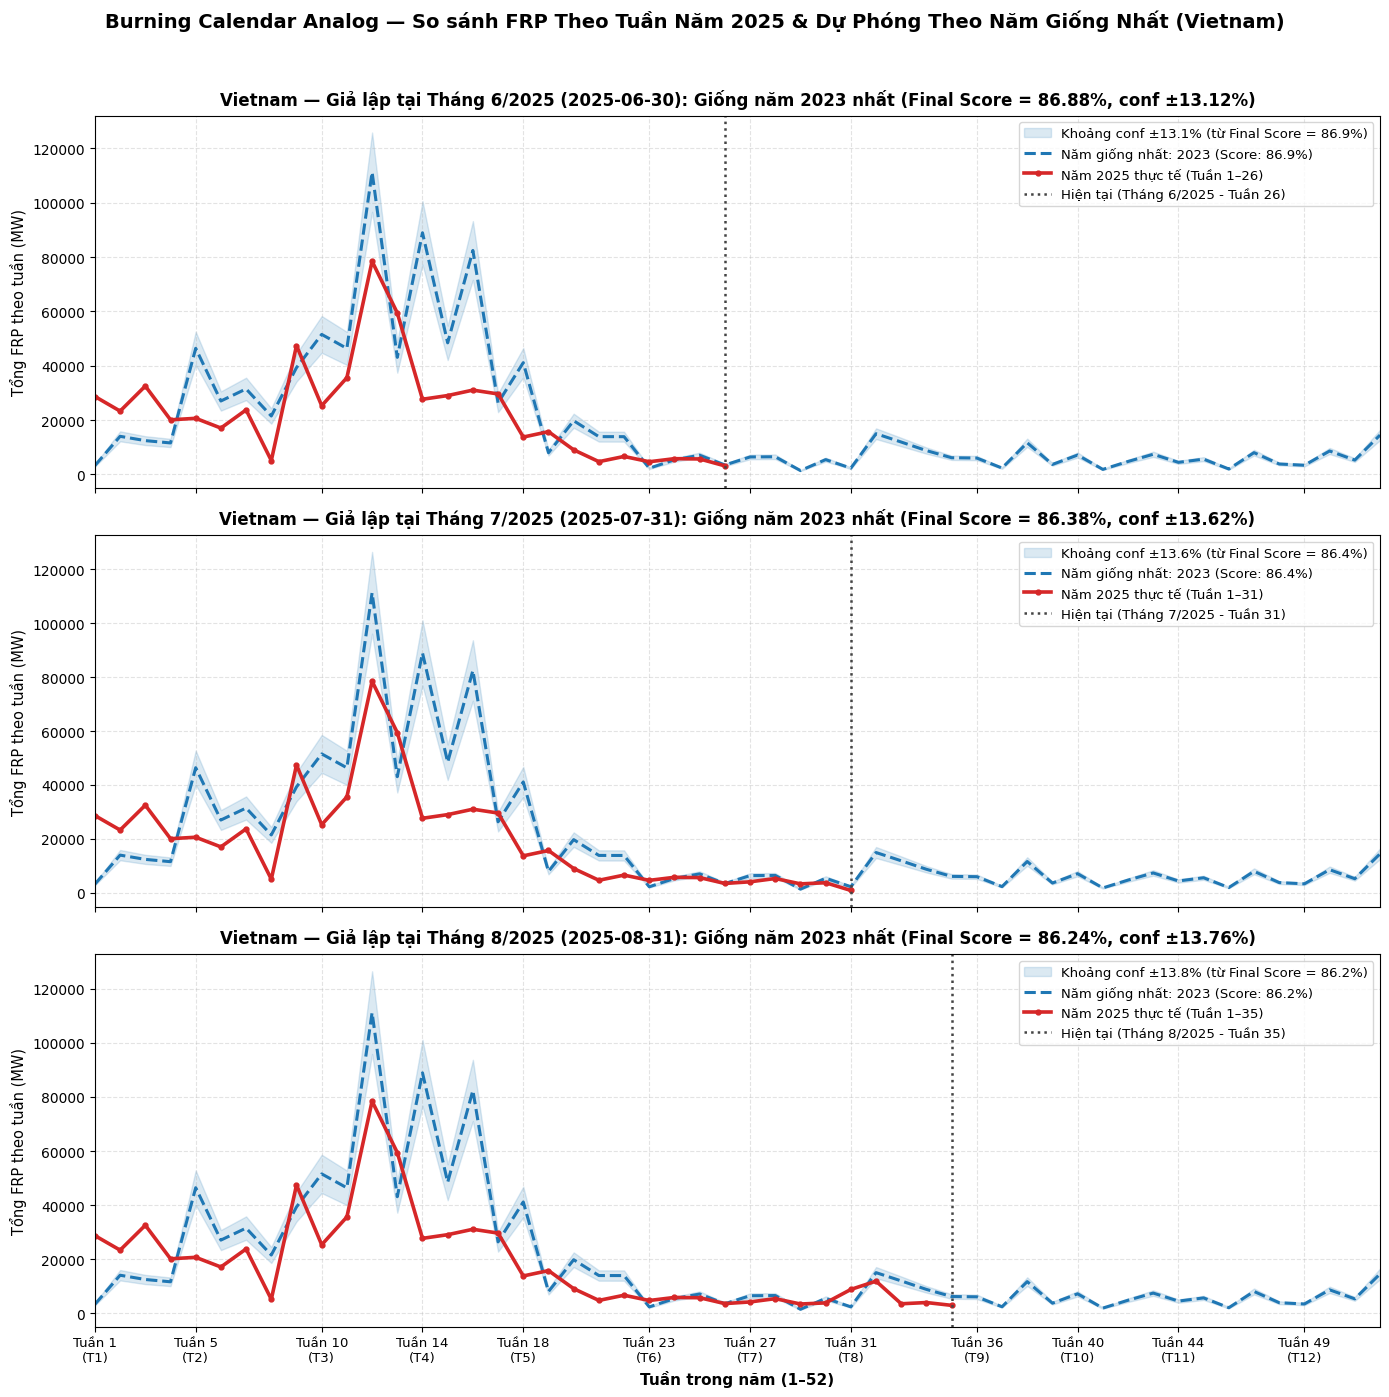

In [3]:
# ==============================================================================
# Ô 4: CHẠY GIẢ LẬP THÁNG 6, 7, 8 NĂM 2025 & VẼ BIỂU ĐỒ FRP THEO TUẦN
# ==============================================================================
COUNTRY = "Vietnam"  # Đổi thành "Brazil", "Indonesia", "United States" hoặc None (Toàn cầu)
TARGET_YEAR = 2025
SIMULATION_CUTOFFS = [
    ("Tháng 6/2025", "2025-06-30"),
    ("Tháng 7/2025", "2025-07-31"),
    ("Tháng 8/2025", "2025-08-31"),
]

scope_label = COUNTRY if COUNTRY is not None else "Toàn cầu (Global)"
weeks_all = np.arange(1, 53)
month_start_weeks = [1, 5, 10, 14, 18, 23, 27, 31, 36, 40, 44, 49]
month_labels = ["T1", "T2", "T3", "T4", "T5", "T6", "T7", "T8", "T9", "T10", "T11", "T12"]

fig, axes = plt.subplots(len(SIMULATION_CUTOFFS), 1, figsize=(14, 14), sharex=True)
if len(SIMULATION_CUTOFFS) == 1:
    axes = [axes]

for ax, (label, cutoff_date) in zip(axes, SIMULATION_CUTOFFS):
    df_upto, df_full, cutoff_doy, cutoff_week = extract_data_for_cutoff(
        parquet_dir=DATA_DIR,
        country=COUNTRY,
        target_year=TARGET_YEAR,
        cutoff_date=cutoff_date,
    )
    ranking_df = rank_similar_years(df_upto, target_year=TARGET_YEAR, cutoff_week=cutoff_week)

    print(f"\n{'=' * 78}")
    print(f"MỐC GIẢ LẬP: {label} (cutoff_date={cutoff_date} | DOY={cutoff_doy} | Tuần {cutoff_week}) | Khu vực: {scope_label}")
    print(f"{'=' * 78}")

    if ranking_df.empty:
        print("Chưa có năm lịch sử (< target_year) để so sánh!")
        ax.set_title(f"{label} — Không có năm lịch sử để so sánh")
        continue

    print("Top 5 năm lịch sử giống nhất:")
    print(ranking_df.head(5).to_string(index=False))

    best = ranking_df.iloc[0]
    best_year = int(best["year"])
    final_score_pct = float(best["final_score_pct"])
    n_pct = float(best["conf_band_pct"])  # Khoảng conf ±n% = 100 - final_score_pct

    # Chuỗi FRP theo tuần của năm hiện tại (Tuần 1..cutoff_week)
    tgt_series = (
        df_upto[df_upto["year"] == TARGET_YEAR]
        .set_index("week_num")["weekly_frp"]
        .reindex(range(1, cutoff_week + 1), fill_value=0.0)
        .to_numpy(dtype=np.float64)
    )
    tgt_weeks = np.arange(1, cutoff_week + 1)

    # Chuỗi FRP đủ 52 tuần của Năm giống nhất
    best_series = (
        df_full[df_full["year"] == best_year]
        .set_index("week_num")["weekly_frp"]
        .reindex(weeks_all, fill_value=0.0)
        .to_numpy(dtype=np.float64)
    )
    lower_band = np.maximum(best_series * (1.0 - n_pct / 100.0), 0.0)
    upper_band = best_series * (1.0 + n_pct / 100.0)

    # 1. Khoảng tin cậy ±n% quanh năm giống nhất
    ax.fill_between(
        weeks_all,
        lower_band,
        upper_band,
        color="#1f77b4",
        alpha=0.16,
        label=f"Khoảng conf ±{n_pct:.1f}% (từ Final Score = {final_score_pct:.1f}%)",
    )
    # 2. Đường nét đứt ---- của Năm giống nhất (đủ 52 tuần)
    ax.plot(
        weeks_all,
        best_series,
        linestyle="--",
        linewidth=2.2,
        color="#1f77b4",
        label=f"Năm giống nhất: {best_year} (Score: {final_score_pct:.1f}%)",
    )
    # 3. Đường liền đậm của Năm 2025 (tới mốc hiện tại)
    ax.plot(
        tgt_weeks,
        tgt_series,
        linestyle="-",
        linewidth=2.6,
        color="#d62728",
        marker="o",
        markersize=3.5,
        label=f"Năm {TARGET_YEAR} thực tế (Tuần 1–{cutoff_week})",
    )
    # 4. Đường thẳng đứng đánh dấu ranh giới hiện tại
    ax.axvline(
        x=cutoff_week,
        color="#444444",
        linestyle=":",
        linewidth=1.8,
        label=f"Hiện tại ({label} - Tuần {cutoff_week})",
    )

    ax.set_title(
        f"{scope_label} — Giả lập tại {label} ({cutoff_date}): "
        f"Giống năm {best_year} nhất (Final Score = {final_score_pct:.2f}%, conf ±{n_pct:.2f}%)",
        fontsize=12,
        fontweight="bold",
        pad=8,
    )
    ax.set_ylabel("Tổng FRP theo tuần (MW)", fontsize=10.5)
    ax.grid(True, linestyle="--", alpha=0.35)
    ax.legend(loc="upper right", fontsize=9.5, frameon=True)
    ax.set_xlim(1, 52)

axes[-1].set_xticks(month_start_weeks)
axes[-1].set_xticklabels([f"Tuần {w}\n({m})" for w, m in zip(month_start_weeks, month_labels)], fontsize=9.5)
axes[-1].set_xlabel("Tuần trong năm (1–52)", fontsize=11, fontweight="bold")

fig.suptitle(
    f"Burning Calendar Analog — So sánh FRP Theo Tuần Năm {TARGET_YEAR} & Dự Phóng Theo Năm Giống Nhất ({scope_label})",
    fontsize=14,
    fontweight="bold",
    y=0.995,
)
plt.tight_layout(rect=[0, 0, 1, 0.975])

country_slug = COUNTRY.lower().replace(" ", "_") if COUNTRY else "global"
out_png = os.path.join(OUTPUT_DIR, f"frp_analog_forecast_{country_slug}_{TARGET_YEAR}.png")
fig.savefig(out_png, dpi=150, bbox_inches="tight")
print(f"\nĐã lưu biểu đồ tại: {out_png}")
plt.show()